# 🌿 Übung: Datenbereinigung bei "GrüneWelt"

## Die Ausgangslage

Ihr seid als Junior Data Analyst:in bei **"GrüneWelt"** eingestiegen, einem Online- und Filialhändler für Pflanzen und Gartenzubehör. Der Vertriebsleiter kommt kurz vor dem Monatsmeeting auf euch zu:

> *"Wir brauchen dringend ein paar Zahlen für das Meeting morgen: In welcher Region läuft das Geschäft am besten? Welche Produkte verkaufen sich gut? Und wie zufrieden sind unsere Kund:innen eigentlich? Ich habe euch den Rohexport aus unserem Bestellsystem rübergeschickt – `pflanzenhandel_bestellungen_rohdaten.csv`."*

Ihr werft einen ersten Blick in die Datei und merkt schnell: **die Daten sind alles andere als sauber.** Bevor ihr überhaupt eine seriöse Analyse abgeben könnt, müsst ihr die Daten aufbereiten – genau wie ihr es heute Vormittag in der Vorlesung gelernt habt.

## Ablauf dieser Übung

Ihr durchlauft dieselben Schritte wie in der Vorlesung, diesmal aber auf dem Pflanzenhandel-Datensatz:

1. Datentypen prüfen und korrigieren
2. Kategorische Werte vereinheitlichen
3. Duplikate identifizieren und entfernen
4. Fehlende Werte analysieren und behandeln
5. Ausreißer / Plausibilität prüfen
6. Dokumentation der Bereinigung
7. **Bonus:** Die eigentliche Frage des Vertriebsleiters beantworten

Bearbeitet die Aufgaben-Zellen selbstständig. Kommt ihr nicht weiter, klappt die **Lösung** darunter auf – aber versucht es erst ehrlich selbst!

## Setup — Aufgabe 0

**Aufgabe:** Importiert `pandas` (als `pd`) und `numpy` (als `np`), ladet den Datensatz `pflanzenhandel_bestellungen_rohdaten.csv` in ein DataFrame `df` und verschafft euch mit zwei euch bekannten Methoden einen ersten Überblick (Anzahl Zeilen/Spalten, Datentypen, erste Zeilen).

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("pflanzenhandel_bestellungen.csv")

df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Bestellnr       123 non-null    int64  
 1   Datum           122 non-null    str    
 2   Kunde           117 non-null    str    
 3   Produkt         123 non-null    str    
 4   Kategorie       123 non-null    str    
 5   Region          114 non-null    str    
 6   Menge           122 non-null    str    
 7   Einzelpreis     118 non-null    float64
 8   Versandart      123 non-null    str    
 9   Vertriebskanal  123 non-null    str    
 10  Bewertung       88 non-null     float64
dtypes: float64(2), int64(1), str(8)
memory usage: 10.7 KB


# 1. Datentypen prüfen und korrigieren

Schaut euch `df.dtypes` bzw. `df.info()` genauer an. Zwei Spalten fallen auf:

* **`Menge`** — sollte eigentlich eine Zahl sein, wird aber als Text (`object`) eingelesen.
* **`Datum`** — sollte ein Datum sein, ist aber ebenfalls nur Text.

**Aufgabe 1.1:** Schaut euch mit `pd.unique()` die Spalte `Menge` an. Welche "komischen" Werte entdeckt ihr?

**Aufgabe 1.2:** Wandelt `Menge` mit `pd.to_numeric()` in einen numerischen Typ um. Nutzt `errors="coerce"`, damit nicht-numerische Werte zu `NaN` werden.

**Aufgabe 1.3:** Wandelt `Datum` mit `pd.to_datetime()` in einen echten Datumstyp um (Format `"%Y-%m-%d"`, ebenfalls mit `errors="coerce"`).

*Hinweis:* Dass dabei ein paar Werte zu `NaN`/`NaT` werden, ist normal und gewollt — um fehlende Werte kümmern wir uns gezielt in Kapitel 3.

In [ ]:
pd.unique(df["Menge"])

df["Menge"] = pd.to_numeric(
    df["Menge"],
    errors="coerce"
)

df["Datum"] = pd.to_datetime(
    df["Datum"],
    format="%Y-%m-%d",
    errors="coerce"
)


Bestellnr                  int64
Datum             datetime64[us]
Kunde                        str
Produkt                      str
Kategorie                    str
Region                       str
Menge                    float64
Einzelpreis              float64
Versandart                   str
Vertriebskanal               str
Bewertung                float64
dtype: object

# 2. Kategorische Werte vereinheitlichen

Der Vertriebsleiter will die Zahlen unter anderem **nach Region** aufschlüsseln. Werft dafür einen Blick auf die eindeutigen Werte in `Region` und `Versandart`.

**Aufgabe 2.1:** Gebt euch mit `pd.unique()` alle Ausprägungen von `Region` und `Versandart` aus. Was fällt euch auf?

**Aufgabe 2.2:** Vereinheitlicht beide Spalten so, dass z.B. `"SÜD"`, `"Süd"` und `"süd"` alle zu **einem** einheitlichen Wert werden (analog für `Versandart`). Nutzt dafür String-Methoden wie `.str.strip()` und `.str.title()` bzw. `.str.upper()` — genau wie in der Vorlesung bei der Spalte `Location`.

*Tipp:* Achtet darauf, dass durch fehlende Werte (`NaN`) in `Region` die String-Methoden nicht crashen — pandas überspringt `NaN` bei `.str`-Methoden automatisch, das ist also kein Problem.

In [8]:
pd.unique(df["Region"])
pd.unique(df["Versandart"])

df["Region"] = (
    df["Region"]
        .str.strip()
        .str.title()
)

df["Versandart"] = (
    df["Versandart"]
        .str.strip()
        .str.title()
)

# 3. Duplikate identifizieren und entfernen

Beim Export aus dem Bestellsystem kann es passieren, dass einzelne Bestellungen versehentlich doppelt exportiert wurden.

**Aufgabe 3.1:** Prüft mit `df.duplicated()`, wie viele exakten Duplikate im Datensatz stecken.

**Aufgabe 3.2:** Entfernt die Duplikate und setzt anschließend den Index zurück (ohne die alte Spalte als neue Spalte zu behalten!).

In [9]:
# 3.1 Anzahl Duplikate prüfen
df.duplicated().sum()

# 3.2 Duplikate entfernen + Index zurücksetzen
df = df.drop_duplicates()
df = df.reset_index(drop=True)



# 4. Fehlende Werte analysieren und behandeln

Jetzt geht es an die fehlenden Werte. Wie in der Vorlesung gilt: **erst verstehen, dann behandeln.**

**Aufgabe 4.1:** Ermittelt mit `df.isna().sum()` die Anzahl fehlender Werte pro Spalte. Berechnet zusätzlich den **prozentualen** Anteil je Spalte (Anzahl fehlend / Gesamtanzahl Zeilen).

In [10]:
# 4.1 Fehlende Werte pro Spalte (absolut & in %)
missing_abs = df.isna().sum()

missing_pct = (
    df.isna().sum()
    / len(df)
    * 100
)

print(missing_abs)
print(missing_pct)

Bestellnr          0
Datum              3
Kunde              5
Produkt            0
Kategorie          0
Region             8
Menge              4
Einzelpreis        5
Versandart         0
Vertriebskanal     0
Bewertung         34
dtype: int64
Bestellnr          0.000000
Datum              2.500000
Kunde              4.166667
Produkt            0.000000
Kategorie          0.000000
Region             6.666667
Menge              3.333333
Einzelpreis        4.166667
Versandart         0.000000
Vertriebskanal     0.000000
Bewertung         28.333333
dtype: float64


## Analyse & Strategie je Spalte

Wahrscheinlich seht ihr fehlende Werte in vier Spalten: `Kunde`, `Region`, `Einzelpreis` und `Bewertung`. Bevor ihr blind `fillna()` aufruft, überlegt euch für **jede** Spalte, ob und wie ihr sie behandelt — genau wie beim `Bonus`/`Salary`/`Gender`-Beispiel in der Vorlesung.

**Aufgabe 4.2 (Diskussion, in eigenen Worten in der Markdown-Zelle darunter beantworten):**

* `Bewertung` fehlt bei recht vielen Bestellungen (~28 %). Überlegt: Ist es hier sinnvoll, den fehlenden Wert durch den Mittelwert/Median zu ersetzen? Oder bedeutet ein fehlender Wert hier eher "Kund:in hat einfach keine Bewertung abgegeben"? Was würde eine Imputation mit dem Mittelwert mit eurer späteren Auswertung der Kundenzufriedenheit machen?
* `Region` fehlt bei wenigen Bestellungen, wird aber für die Analyse "Umsatz nach Region" gebraucht. Löschen oder mit einer Kategorie wie `"Unbekannt"` auffüllen?
* `Einzelpreis` fehlt nur bei ein paar Zeilen. Sollte man hier eher den **Median über den gesamten Datensatz** nehmen, oder gibt es einen Trick, der genauer wäre (Tipp: Preise unterscheiden sich stark je `Produkt` — was, wenn ihr den Median *pro Produkt* nutzt)?
* `Kunde` fehlt bei ein paar Zeilen. Braucht ihr diese Spalte überhaupt für die Fragen des Vertriebsleiters?

*(Eure Antwort/Diskussion hier eintragen)*

- Bewertung: ...
- Region: ...
- Einzelpreis: ...
- Kunde: ...

**Aufgabe 4.3:** Setzt eure Strategie um. Erstellt einen bereinigten DataFrame `df_clean`:

* `Region`: fehlende Werte mit `"Unbekannt"` auffüllen
* `Kunde`: fehlende Werte mit `"Unbekannt"` auffüllen
* `Einzelpreis`: fehlende Werte mit dem **Median pro Produkt** auffüllen
* `Bewertung`: **nicht** auffüllen — bleibt bewusst `NaN`, wird bei Bedarf mit `dropna()` behandelt

Kontrolliert anschließend mit `df_clean.isna().sum()`, ob alles wie geplant aussieht.

In [ ]:
# 4.3 df_clean erstellen und fehlende Werte behandeln

df_clean = df.copy()

df_clean["Region"] = (
    df_clean["Region"]
    .fillna("Unbekannt")
)

df_clean["Kunde"] = (
    df_clean["Kunde"]
    .fillna("Unbekannt")
)

median_prices = (
    df_clean
    .groupby("Produkt")["Einzelpreis"]
    .transform("median")
)

df_clean["Einzelpreis"] = (
    df_clean["Einzelpreis"]
    .fillna(median_prices)
)

df_clean.isna().sum()


Bestellnr          0
Datum              3
Kunde              0
Produkt            0
Kategorie          0
Region             0
Menge              4
Einzelpreis        0
Versandart         0
Vertriebskanal     0
Bewertung         34
dtype: int64

# 5. Ausreißer / Plausibilität prüfen

**Aufgabe 5.1:** Lasst euch `df_clean.describe()` für die numerischen Spalten ausgeben. Erstellt zusätzlich einen Boxplot für die Spalte `Menge` (`df_clean.boxplot(column="Menge")`). Was fällt euch auf?

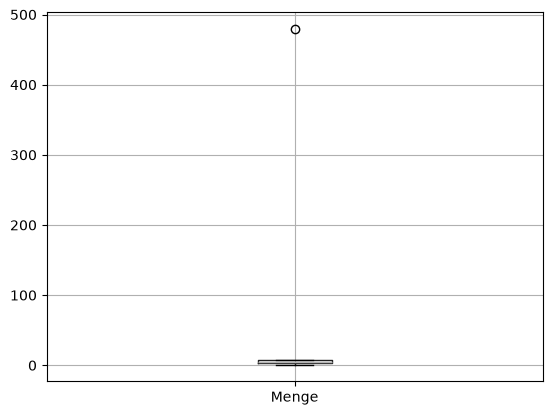

In [12]:
# 5.1 describe() und Boxplot für 'Menge'
import matplotlib.pyplot as plt

df_clean.boxplot(column="Menge")

plt.show()


**Aufgabe 5.2:** Es gibt vermutlich eine Bestellung mit einer auffällig hohen `Menge`. Findet die entsprechende Zeile (Tipp: `df_clean["Menge"].idxmax()`) und schaut euch an, welche:r Kund:in dahintersteckt. Prüft anschließend, ob diese:r Kund:in generell größere Mengen bestellt (z.B. mit `df_clean[df_clean["Kunde"] == "..."]`), bevor ihr entscheidet, ob es sich um einen plausiblen Wert oder einen Fehler handelt.

In [13]:
# 5.2 Auffällige Bestellung untersuchen

max_index = df_clean["Menge"].idxmax()

df_clean.loc[max_index]

Bestellnr                        2009
Datum             2025-05-28 00:00:00
Kunde                             Ben
Produkt                     Bogenhanf
Kategorie              Zimmerpflanzen
Region                            Süd
Menge                           480.0
Einzelpreis                     21.76
Versandart                    Express
Vertriebskanal            Online-Shop
Bewertung                         5.0
Name: 18, dtype: object

# 6. Dokumentation der Bereinigung

Der Vertriebsleiter kennt sich mit Python nicht aus, will aber nachvollziehen können, was mit den Daten gemacht wurde, bevor er sich auf eure Zahlen verlässt.

**Aufgabe 6.1:** Dokumentiert stichpunktartig (in der Markdown-Zelle darunter), welche Bereinigungsschritte ihr durchgeführt habt und warum.

*(Eure Dokumentation hier eintragen)*

- ...
- ...
- ...

# 🎯 Bonus: Beantwortet die Frage des Vertriebsleiters

Jetzt, wo `df_clean` bereinigt ist, könnt ihr endlich liefern! Nutzt `df_clean`, um folgende Fragen zu beantworten:

**Aufgabe 7.1:** Berechnet für jede Bestellung den `Umsatz` (`Menge * Einzelpreis`) als neue Spalte.

**Aufgabe 7.2:** Welche `Region` hat den höchsten Gesamtumsatz? (Gruppiert nach `Region`, summiert `Umsatz`.)

**Aufgabe 7.3:** Welches `Produkt` wurde am häufigsten bestellt (nach Gesamtmenge)?

**Aufgabe 7.4:** Wie hoch ist die durchschnittliche Kundenbewertung — **unter den Kund:innen, die überhaupt bewertet haben**?

In [ ]:
# 7.1 Umsatz-Spalte berechnen


# 7.2 Umsatz nach Region


# 7.3 Beliebtestes Produkt nach Menge


# 7.4 Durchschnittliche Bewertung (nur vorhandene Bewertungen)



## Fazit

Ihr habt es geschafft: aus einem unbereinigten Rohexport wurde eine belastbare Grundlage für das Vertriebsmeeting. Dabei habt ihr geübt:

* Datentypen erkennen und korrigieren
* Kategorische Werte vereinheitlichen
* Duplikate identifizieren und entfernen
* Fehlende Werte differenziert analysieren und behandeln (statt blind aufzufüllen!)
* Ausreißer kritisch auf Plausibilität prüfen
* Die eigene Bereinigung für Nicht-Techniker:innen dokumentieren

Genau dieser Ablauf — **verstehen, bevor man handelt** — ist der Kern jeder guten Exploративen Datenanalyse (EDA).